# A/B Test Analysis and Insights

SollmaFin is an international mobile and web app for trading financial assets (stocks, currencies, crypto, ETFs). Its target audience is beginner investors, and it focuses on four Latin American markets: Mexico, Brazil, Colombia and Argentina.

**Problem.** The product team suspects that users lack financial literacy: they buy high-risk assets without understanding them, lose money and disengage. The team updated the onboarding to explain asset types and their risks. The concern is that a more detailed onboarding may scare users away from making a deposit and from riskier investments.

**Experiment.** New users who registered between 2 and 15 June 2025 were randomly split into two equal groups and observed for a week.
- **Control:** standard onboarding.
- **Test:** updated onboarding with detailed information about assets and risks.

**Hypotheses**
- *Growth:* educational onboarding helps users understand investing, so they open a second deposit more often.
- *Risk:* information about possible losses scares off cautious newcomers, lowering conversion to the first deposit.
- *Additional:* users who choose high-risk assets will return and make a second deposit more often than before, because they now understand the consequences.

**Metrics**
- *Key metric:* average total deposit amount per user (including everyone who installed the app or opened the web version).
- *Guardrail metric:* conversion from registration to first deposit.
- *Supporting metric 1:* conversion from first to second deposit.
- *Supporting metric 2:* average total deposit amount per user with at least one deposit.

The key and guardrail metrics are expected not to drop, while the supporting metrics are expected to grow.

**Data**
- Historical data: key actions of new users acquired from 1 April to 1 June 2025 (actions up to the second deposit).
- A/B test data: all actions of new users who registered from 2 to 15 June 2025, already assigned to groups.

Main fields: `user_id`, `country_code` (ISO code: BR, MX, AR, CO), `platform` (mobile / web), `first_ts` and `first_dt` (first appearance), `event_ts` and `event_name`, `amount` (deposit amount), `asset` (asset type), `risk_level` (low / medium / high). The A/B dataset also has `ab_test` and `group`.

**Project plan**
1. Load and preprocess historical data
2. Exploratory analysis of historical data
3. A/B test results
4. Change in deposit amount per paying user (bootstrap)
5. Conclusions

---

## Part 1

### 1. Loading and preprocessing historical data

In [2]:
from statsmodels.stats.proportion import proportions_ztest
from scipy.stats import ttest_ind
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv('https://code.s3.yandex.net/datasets/pa_sollmafin_hist.csv')

print(df.duplicated().sum())

dtimes = ['first_ts', 'event_ts']
for time in dtimes:
    df[time] = pd.to_datetime(df[time])


print(df.head())
print(df.info())

0
                                user_id country_code platform  \
0  548ac59f-656d-4110-80d2-49f0a217f08a           BR   mobile   
1  548ac59f-656d-4110-80d2-49f0a217f08a           BR   mobile   
2  548ac59f-656d-4110-80d2-49f0a217f08a           BR   mobile   
3  548ac59f-656d-4110-80d2-49f0a217f08a           BR   mobile   
4  548ac59f-656d-4110-80d2-49f0a217f08a           BR   mobile   

             first_ts    first_dt            event_ts           event_name  \
0 2025-04-02 19:55:51  2025-04-02 2025-04-02 19:55:51   install / open_web   
1 2025-04-02 19:55:51  2025-04-02 2025-04-02 19:55:59         introduction   
2 2025-04-02 19:55:51  2025-04-02 2025-04-02 23:46:06         registration   
3 2025-04-02 19:55:51  2025-04-02 2025-04-02 23:46:15            main_page   
4 2025-04-02 19:55:51  2025-04-02 2025-04-02 23:47:59  onboarding_complete   

   amount asset risk_level  
0     NaN   NaN        NaN  
1     NaN   NaN        NaN  
2     NaN   NaN        NaN  
3     NaN   NaN       

No duplicates were found during preprocessing. `first_ts` and `event_ts` were converted to datetime64.

---

### 2. Exploratory analysis of historical data

**Task 2.1.** New users: acquisition dynamics.

      first_dt  user_id
0   2025-04-01      670
1   2025-04-02      676
2   2025-04-03      691
3   2025-04-04      637
4   2025-04-05      640
..         ...      ...
57  2025-05-28      648
58  2025-05-29      673
59  2025-05-30      622
60  2025-05-31      640
61  2025-06-01      649

[62 rows x 2 columns]


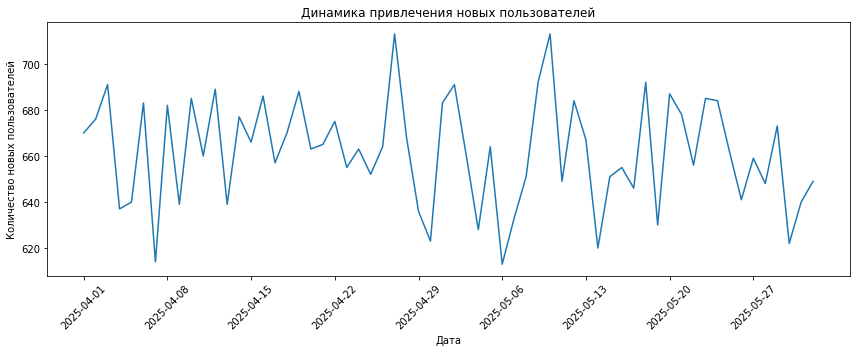

In [4]:
new_users = df.groupby('first_dt')['user_id'].nunique().reset_index()

print(new_users)

plt.figure(figsize=(12, 5))
plt.plot(new_users['first_dt'], new_users['user_id'])
plt.title('New user acquisition dynamics')
plt.xlabel('Date')
plt.ylabel('Number of new users')
plt.xticks(new_users['first_dt'][::7], rotation=45)  # every 7th date
plt.tight_layout()
plt.show()

The chart shows that new-user acquisition is quite volatile (from about 600 to over 700 new users per day), although it stays around 660.

**Task 2.2.** Event funnels.
- Build the classic and step-by-step funnels.
- Describe the user path and identify bottlenecks.

In [5]:
print(df['event_name'].unique())

['install / open_web' 'introduction' 'registration' 'main_page'
 'onboarding_complete' 'first_deposit' 'asset_purchase' 'second_deposit']


In [6]:
steps = ['install / open_web', 'introduction', 'registration', 'main_page',
 'onboarding_complete', 'first_deposit', 'asset_purchase', 'second_deposit']

def build_funnel_previous(df, steps, title='Step-by-step funnel: conversion from previous step'):
    funnel_df_steps = df[df['event_name'].isin(steps)]
    funnel_counts = funnel_df_steps.groupby('event_name')['user_id'].nunique().reindex(steps)
    
    funnel_df = pd.DataFrame({
        'step' : steps,
        'users' : funnel_counts.values
    })
    
    funnel_df['conversion_from_previous_%'] = (funnel_df['users'] / funnel_df['users'].shift(1) * 100).round(1)
    
    display(funnel_df)


    plt.figure(figsize=(10, 6))

    plt.bar(funnel_df['step'][1:], funnel_df['conversion_from_previous_%'][1:])

    #plt.title('Step-by-step funnel: conversion from previous step')
    plt.title(title)
    plt.ylabel('Conversion from previous step (%)')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
    
def build_funnel_first(df, steps, title='Classic funnel: conversion by stage'):
    funnel_df_steps = df[df['event_name'].isin(steps)]
    funnel_counts = funnel_df_steps.groupby('event_name')['user_id'].nunique().reindex(steps)

    funnel_df = pd.DataFrame({
        'step' : steps,
        'users' : funnel_counts.values
    })

    funnel_df['conversion_from_first_%'] = (funnel_df['users'] / funnel_df['users'].iloc[0] * 100).round(1)

    display(funnel_df)

    plt.figure(figsize=(10, 6))

    plt.bar(funnel_df['step'][0:], funnel_df['conversion_from_first_%'][0:])

    #plt.title('Classic funnel: conversion by stage')
    plt.title(title)
    plt.ylabel('Conversion from previous step (%)')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

,step,users,conversion_from_first_%
0,install / open_web,41032,100.0
1,introduction,41032,100.0
2,registration,38133,92.9
3,main_page,35040,85.4
4,onboarding_complete,34337,83.7
5,first_deposit,27685,67.5
6,asset_purchase,15392,37.5
7,second_deposit,5408,13.2


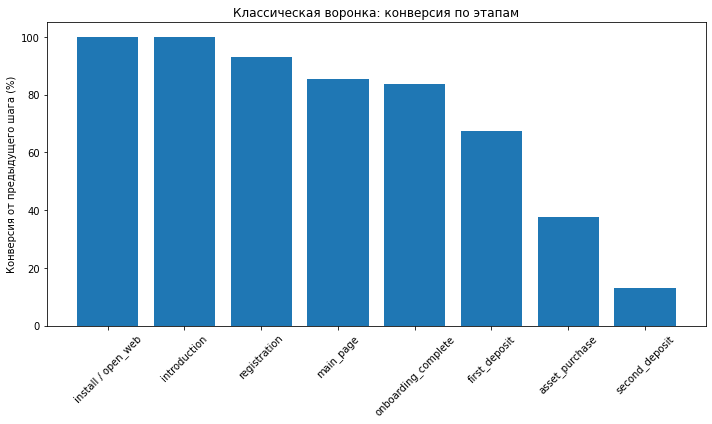

In [7]:
build_funnel_first(df, steps)

The main losses begin after the first deposit. Most of the audience reaches that stage, but conversion then drops noticeably: far fewer users make an asset purchase, and especially a second deposit.

,step,users,conversion_from_previous_%
0,install / open_web,41032,NaN
1,introduction,41032,100.0
2,registration,38133,92.9
3,main_page,35040,91.9
4,onboarding_complete,34337,98.0
5,first_deposit,27685,80.6
6,asset_purchase,15392,55.6
7,second_deposit,5408,35.1


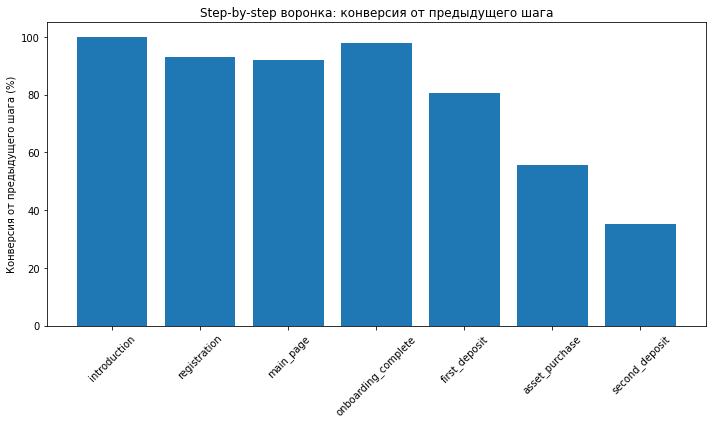

In [8]:
build_funnel_previous(df, steps)

The largest conversion drops are between the first deposit and the asset purchase, and then between the asset purchase and the second deposit. Users most often stop progressing right after their first top-up.

**Task 2.3.** Effect of the risk level on the second deposit.
- How does the risk level of the first asset affect conversion to the second deposit?

In [9]:
def risk_calc(df):
    purchase_df = df[df['event_name'] == 'asset_purchase'].copy()
    second_deposit_df = df[df['event_name'] == 'second_deposit'].copy()

    first_purchase_idx = purchase_df.groupby('user_id')['event_ts'].idxmin()
    first_purchase = purchase_df.loc[first_purchase_idx, ['user_id', 'risk_level']].copy()

    second_deposit_users = second_deposit_df[['user_id']].drop_duplicates()
    second_deposit_users['made_second_deposit'] = 1

    # 3. merge
    risk_conversion = first_purchase.merge(second_deposit_users, on='user_id', how='left')

    # 4. if there was no second deposit, set 0
    risk_conversion['made_second_deposit'] = risk_conversion['made_second_deposit'].fillna(0)

    # 5. calculate conversion by risk level
    result = (
        risk_conversion.groupby('risk_level')
        .agg(
            users_with_first_asset=('user_id', 'nunique'),
            users_with_second_deposit=('made_second_deposit', 'sum')
        )
        .reset_index()
    )

    result['conversion_to_second_deposit_%'] = (
        result['users_with_second_deposit'] / result['users_with_first_asset'] * 100
    ).round(2)

    print(result)

risk_calc(df)

  risk_level  users_with_first_asset  users_with_second_deposit  \
0       high                    7740                     2040.0   
1        low                    2327                     1080.0   
2     medium                    5325                     2288.0   

   conversion_to_second_deposit_%  
0                           26.36  
1                           46.41  
2                           42.97  


Users whose first asset is high-risk open a second deposit almost half as often as users with low- or medium-risk assets. There is no noticeable difference between the low and medium groups. This suggests that a higher-risk first asset reduces the chance of further top-ups.

**Task 2.4.** Key metric on historical data.
- Calculate the average total deposit amount per user, counting all users who interacted with the service. This sets the baseline level of monetization.
- Visualize the data and summarize the findings.

In [10]:
user_revenue = df.groupby('user_id')['amount'].sum()

avg_deposit_per_user = user_revenue.mean()
std_deposit_per_user = user_revenue.std()

print('All time revenue per user:', avg_deposit_per_user)
print('All time std:', std_deposit_per_user)

All time revenue per user: 91.5622197309417
All time std: 80.39325051096466


In [11]:
daily_user_revenue = (
    df.groupby([df['event_ts'].dt.date, 'user_id'])['amount']
    .sum()
    .reset_index()
)

avg_deposit_per_user_daily = (
    daily_user_revenue.groupby('event_ts')['amount']
    .mean()
)

std_deposit_per_user_daily = (
    daily_user_revenue.groupby('event_ts')['amount']
    .std()
)

print('Daily revenue per user:')
print(avg_deposit_per_user_daily)

print('Daily std:')
print(std_deposit_per_user_daily)

Daily revenue per user:
event_ts
2025-04-01      2.697015
2025-04-02     23.424184
2025-04-03     35.854260
2025-04-04     38.294078
2025-04-05     35.810904
                 ...    
2025-06-05     79.789916
2025-06-06    116.333333
2025-06-07    124.200000
2025-06-08    130.666667
2025-06-09    154.666667
Name: amount, Length: 70, dtype: float64
Daily std:
event_ts
2025-04-01    16.902671
2025-04-02    47.204610
2025-04-03    56.736348
2025-04-04    55.567747
2025-04-05    55.495086
                ...    
2025-06-05    71.483182
2025-06-06    48.368866
2025-06-07    56.571489
2025-06-08    53.809541
2025-06-09    44.601943
Name: amount, Length: 70, dtype: float64


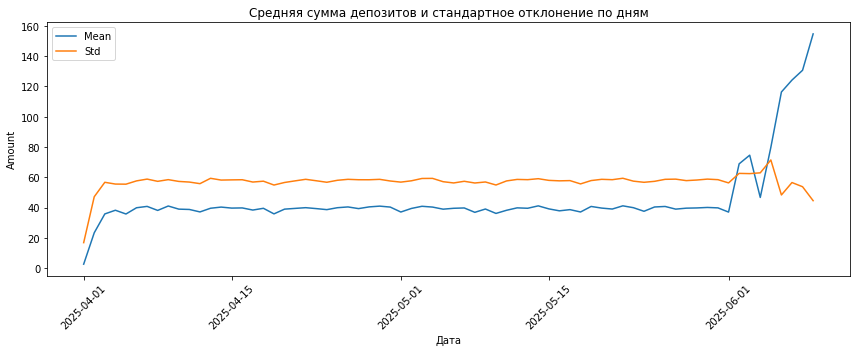

In [12]:
plt.figure(figsize=(12, 5))
plt.plot(avg_deposit_per_user_daily.index, avg_deposit_per_user_daily.values, label='Mean')
plt.plot(std_deposit_per_user_daily.index, std_deposit_per_user_daily.values, label='Std')

plt.title('Mean deposit amount and standard deviation by day')
plt.xlabel('Date')
plt.ylabel('Amount')
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

The average deposit amount per user was stable for most of the period but rose sharply in early June. The high standard deviation shows a wide spread of values, so the average may depend on a few large deposits.

---

## Part 2

### 3. A/B test results

Load the experiment data, check it and preprocess it, then analyze the results.

In [13]:
df_new = pd.read_csv('https://code.s3.yandex.net/datasets/pa_sollmafin_abt.csv')

print(df.duplicated().sum())

dtimes = ['first_ts', 'event_ts']
for time in dtimes:
    df[time] = pd.to_datetime(df[time])


print(df.head())
print(df.info())

0
                                user_id country_code platform  \
0  548ac59f-656d-4110-80d2-49f0a217f08a           BR   mobile   
1  548ac59f-656d-4110-80d2-49f0a217f08a           BR   mobile   
2  548ac59f-656d-4110-80d2-49f0a217f08a           BR   mobile   
3  548ac59f-656d-4110-80d2-49f0a217f08a           BR   mobile   
4  548ac59f-656d-4110-80d2-49f0a217f08a           BR   mobile   

             first_ts    first_dt            event_ts           event_name  \
0 2025-04-02 19:55:51  2025-04-02 2025-04-02 19:55:51   install / open_web   
1 2025-04-02 19:55:51  2025-04-02 2025-04-02 19:55:59         introduction   
2 2025-04-02 19:55:51  2025-04-02 2025-04-02 23:46:06         registration   
3 2025-04-02 19:55:51  2025-04-02 2025-04-02 23:46:15            main_page   
4 2025-04-02 19:55:51  2025-04-02 2025-04-02 23:47:59  onboarding_complete   

   amount asset risk_level  
0     NaN   NaN        NaN  
1     NaN   NaN        NaN  
2     NaN   NaN        NaN  
3     NaN   NaN       

No duplicates were found during preprocessing. `first_ts` and `event_ts` were converted to datetime64.

**Task 3.1.** Experiment audience.
- Check that new users were correctly distributed between the groups.
- Build charts and summarize.

In [14]:
flawed_users = df_new.groupby('user_id')['group'].nunique().reset_index()
flawed_users = flawed_users[flawed_users['group'] > 1]

df_new_correct = df_new[~df_new['user_id'].isin(flawed_users['user_id'])]

print(flawed_users)
print(f"Users after cleaning: {df_new_correct['user_id'].nunique()}")

Empty DataFrame
Columns: [user_id, group]
Index: []
Количество пользователей после очистки: 9415


group
control    4847
test       4568
Name: user_id, dtype: int64
      first_dt    group  user_id
0   2025-06-02  control      364
1   2025-06-02     test      360
2   2025-06-03  control      341
3   2025-06-03     test      325
4   2025-06-04  control      347
5   2025-06-04     test      323
6   2025-06-05  control      363
7   2025-06-05     test      335
8   2025-06-06  control      313
9   2025-06-06     test      335
10  2025-06-07  control      349
11  2025-06-07     test      308
12  2025-06-08  control      376
13  2025-06-08     test      332
14  2025-06-09  control      346
15  2025-06-09     test      325
16  2025-06-10  control      302
17  2025-06-10     test      343
18  2025-06-11  control      359
19  2025-06-11     test      305
20  2025-06-12  control      332
21  2025-06-12     test      332
22  2025-06-13  control      349
23  2025-06-13     test      301
24  2025-06-14  control      358
25  2025-06-14     test      339
26  2025-06-15  control      348
27  2025-0

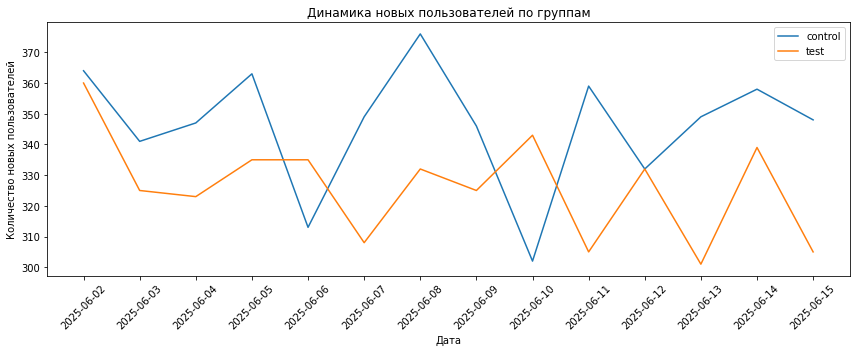

In [15]:
users_by_group = df_new_correct.groupby('group')['user_id'].nunique()
users_by_day_group = df_new_correct.groupby(['first_dt', 'group'])['user_id'].nunique().reset_index()

print(users_by_group)
print(users_by_day_group)

plt.figure(figsize=(12, 5))

for group in users_by_day_group['group'].unique():
    group_data = users_by_day_group[users_by_day_group['group'] == group]
    plt.plot(group_data['first_dt'], group_data['user_id'], label=group)
    
plt.title('New user dynamics by group')
plt.xlabel('Date')
plt.ylabel('Number of new users')
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

The distribution of new users between the experiment groups looks correct. The group sizes are close, and the daily acquisition dynamics are comparable, with no obvious failures or anomalous skews.

**Task 3.2.** Funnel comparison.
- Compare the user path in the test and control groups.
- Build the classic and step-by-step funnels, visualize them and summarize.

In [16]:
df_new_correct_test = df_new_correct[df_new_correct['group'] == 'test'].copy()
df_new_correct_control = df_new_correct[df_new_correct['group'] == 'control'].copy()

In [17]:
#build_funnel_first(df_new_correct_test, steps, title='Classic funnel: Test group')

In [18]:
#build_funnel_first(df_new_correct_control, steps, title='Classic funnel: Control group')

In [19]:
#build_funnel_previous(df_new_correct_test, steps, title='Classic funnel: Test group')

In [20]:
#build_funnel_previous(df_new_correct_control, steps, title='Classic funnel: Control group')

,step,Test,Control
0,install / open_web,100.0,100.0
1,introduction,100.0,100.0
2,registration,93.4,93.1
3,main_page,85.8,85.8
4,onboarding_complete,75.8,83.8
5,first_deposit,65.4,66.6
6,asset_purchase,43.3,36.6
7,second_deposit,21.3,13.5


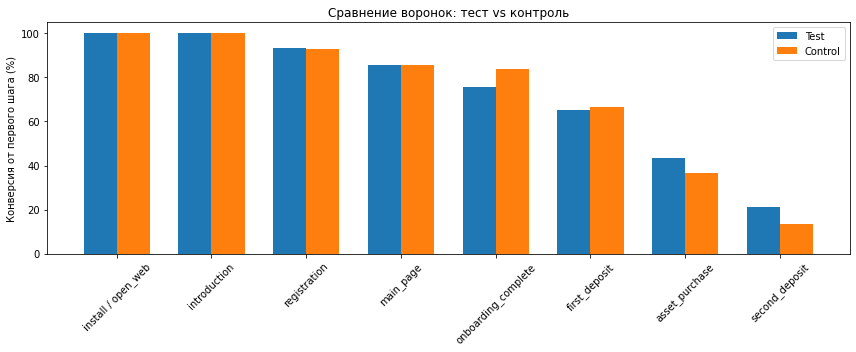

,step,Test,Control
0,install / open_web,NaN,NaN
1,introduction,100.0,100.0
2,registration,93.4,93.1
3,main_page,91.9,92.2
4,onboarding_complete,88.3,97.6
5,first_deposit,86.3,79.4
6,asset_purchase,66.2,54.9
7,second_deposit,49.3,36.9


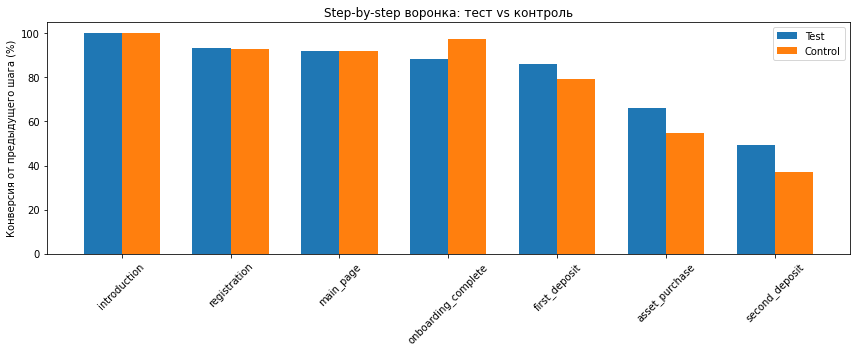

In [21]:
def build_funnel_compare(df1, df2, steps, label1='Group 1', label2='Group 2',
                         title='Funnel comparison'):
    funnel_1 = df1[df1['event_name'].isin(steps)].groupby('event_name')['user_id'].nunique().reindex(steps)
    funnel_2 = df2[df2['event_name'].isin(steps)].groupby('event_name')['user_id'].nunique().reindex(steps)

    conv_1 = (funnel_1 / funnel_1.iloc[0] * 100).round(1)
    conv_2 = (funnel_2 / funnel_2.iloc[0] * 100).round(1)

    plot_df = pd.DataFrame({
        'step': steps,
        label1: conv_1.values,
        label2: conv_2.values
    })

    display(plot_df)

    x = np.arange(len(steps))
    width = 0.35

    plt.figure(figsize=(12, 5))
    plt.bar(x - width/2, plot_df[label1], width=width, label=label1)
    plt.bar(x + width/2, plot_df[label2], width=width, label=label2)

    plt.title(title)
    plt.ylabel('Conversion from first step (%)')
    plt.xticks(x, steps, rotation=45)
    plt.legend()
    plt.tight_layout()
    plt.show()
    
build_funnel_compare(
    df_new_correct_test,
    df_new_correct_control,
    steps,
    label1='Test',
    label2='Control',
    title='Funnel comparison: test vs control'
)

def build_funnel_previous_compare(df1, df2, steps, label1='Group 1', label2='Group 2',
                         title='Step-by-step funnel comparison'):
    funnel_1 = df1[df1['event_name'].isin(steps)].groupby('event_name')['user_id'].nunique().reindex(steps)
    funnel_2 = df2[df2['event_name'].isin(steps)].groupby('event_name')['user_id'].nunique().reindex(steps)

    conv_1 = (funnel_1 / funnel_1.shift(1) * 100).round(1)
    conv_2 = (funnel_2 / funnel_2.shift(1) * 100).round(1)

    plot_df = pd.DataFrame({
        'step': steps,
        label1: conv_1.values,
        label2: conv_2.values
    })

    display(plot_df)

    x = np.arange(len(steps) - 1)
    width = 0.35

    plt.figure(figsize=(12, 5))
    plt.bar(x - width/2, plot_df[label1][1:], width=width, label=label1)
    plt.bar(x + width/2, plot_df[label2][1:], width=width, label=label2)

    plt.title(title)
    plt.ylabel('Conversion from previous step (%)')
    plt.xticks(x, steps[1:], rotation=45)
    plt.legend()
    plt.tight_layout()
    plt.show()

build_funnel_previous_compare(
    df_new_correct_test,
    df_new_correct_control,
    steps,
    label1='Test',
    label2='Control',
    title='Step-by-step funnel: test vs control'
)

Up to the `main_page` step the differences between the groups are minimal. The main deterioration in the test group occurs at the transition to `onboarding_complete`. At later stages, however, the test group converts better, especially at `asset_purchase` and `second_deposit`. This may mean that the test made part of the users drop out at the middle stage but improved the quality of those who reached the lower stages of the funnel.

**Task 3.3.** Effect of the new feature on second deposit conversion, by risk level of the purchased asset.
- Analyze how the risk level affects the probability of a second deposit in the test and control groups.
- Compare the results and check whether the difference between the groups is statistically significant.

In [22]:
dtimes = ['first_ts', 'event_ts']
for time in dtimes:
    df_new_correct_test[time] = pd.to_datetime(df_new_correct_test[time])
    
for time in dtimes:
    df_new_correct_control[time] = pd.to_datetime(df_new_correct_control[time])

risk_calc(df_new_correct_test)
risk_calc(df_new_correct_control)

  risk_level  users_with_first_asset  users_with_second_deposit  \
0       high                     737                      339.0   
1        low                     496                      285.0   
2     medium                     744                      350.0   

   conversion_to_second_deposit_%  
0                           46.00  
1                           57.46  
2                           47.04  
  risk_level  users_with_first_asset  users_with_second_deposit  \
0       high                     893                      247.0   
1        low                     285                      142.0   
2     medium                     595                      265.0   

   conversion_to_second_deposit_%  
0                           27.66  
1                           49.82  
2                           44.54  


H0: conversion to the second deposit is the same in the test and control groups for each risk level.

H1: conversion to the second deposit differs between the groups.

In [23]:
from statsmodels.stats.proportion import proportions_ztest

alpha = 0.05

risk_levels = df_new_correct_test['risk_level'].dropna().unique()

for risk in risk_levels:
    test_users = df_new_correct_test[
        (df_new_correct_test['event_name'] == 'asset_purchase') &
        (df_new_correct_test['risk_level'] == risk)
    ]['user_id'].unique()

    control_users = df_new_correct_control[
        (df_new_correct_control['event_name'] == 'asset_purchase') &
        (df_new_correct_control['risk_level'] == risk)
    ]['user_id'].unique()

    test_second = df_new_correct_test[
        (df_new_correct_test['event_name'] == 'second_deposit') &
        (df_new_correct_test['user_id'].isin(test_users))
    ]['user_id'].nunique()

    control_second = df_new_correct_control[
        (df_new_correct_control['event_name'] == 'second_deposit') &
        (df_new_correct_control['user_id'].isin(control_users))
    ]['user_id'].nunique()

    stat, p_value = proportions_ztest(
        [test_second, control_second],
        [len(test_users), len(control_users)]
    )

    print(f'Risk level: {risk}')
    print(f'p-value = {p_value:.4f}')

    if p_value > alpha:
        print(f'p-value = {p_value:.4f} > {alpha}')
        print('No statistically significant differences found')
        print('No grounds to reject the null hypothesis')
    else:
        print(f'p-value = {p_value:.4f} <= {alpha}')
        print('The differences are statistically significant')
        print('Reject the null hypothesis')

    print()

Risk level: high
p-value = 0.0000
p-value = 0.0000 <= 0.05
Различия статистически значимы
Отвергаем нулевую гипотезу

Risk level: low
p-value = 0.0391
p-value = 0.0391 <= 0.05
Различия статистически значимы
Отвергаем нулевую гипотезу

Risk level: medium
p-value = 0.3607
p-value = 0.3607 > 0.05
Статистически значимых различий не обнаружено
Нет оснований отвергнуть нулевую гипотезу



For high- and low-risk assets, the differences between the test and control groups in conversion to the second deposit are statistically significant.

For medium-risk assets, no significant difference between the groups was found.

**Task 3.4.** A/B test metrics.
- *Key metric:* average total deposit amount per user (including those who installed the app or opened the web version).
- *Guardrail metric:* conversion from registration to first deposit.
- *Supporting metric 1:* conversion from first to second deposit.
- *Supporting metric 2:* average total deposit amount per user with at least one deposit.

For each metric: values in both groups, and absolute and relative change in the test group vs. control. Then test the statistical significance of the differences. For the key metric, also look at the cumulative dynamics by day and the stability of the p-value.

In [24]:
# Key metric
arpu_control = df_new_correct_control['amount'].sum() / df_new_correct_control['user_id'].nunique()
arpu_test = df_new_correct_test['amount'].sum() / df_new_correct_test['user_id'].nunique()

# Guardrail metric
cr_control = (
    df_new_correct_control[df_new_correct_control['event_name'] == 'first_deposit']['user_id'].nunique()
    / df_new_correct_control[df_new_correct_control['event_name'] == 'registration']['user_id'].nunique()
)
cr_test = (
    df_new_correct_test[df_new_correct_test['event_name'] == 'first_deposit']['user_id'].nunique()
    / df_new_correct_test[df_new_correct_test['event_name'] == 'registration']['user_id'].nunique()
)

# Supporting metrics
cr_sec_control = (
    df_new_correct_control[df_new_correct_control['event_name'] == 'second_deposit']['user_id'].nunique()
    / df_new_correct_control[df_new_correct_control['event_name'] == 'first_deposit']['user_id'].nunique()
)

cr_sec_test = (
    df_new_correct_test[df_new_correct_test['event_name'] == 'second_deposit']['user_id'].nunique() 
    / df_new_correct_test[df_new_correct_test['event_name'] == 'first_deposit']['user_id'].nunique()
)

arppu_control = (
    df_new_correct_control['amount'].sum()
    / df_new_correct_control[df_new_correct_control['event_name'] == 'first_deposit']['user_id'].nunique()
)

arppu_test = (
    df_new_correct_test['amount'].sum()
    / df_new_correct_test[df_new_correct_test['event_name'] == 'first_deposit']['user_id'].nunique()
)

print(f'ARPU: control = {arpu_control:.4f}, test = {arpu_test:.4f}')
print(f'CR reg -> first deposit: control = {cr_control:.4f}, test = {cr_test:.4f}')
print(f'CR first -> second deposit: control = {cr_sec_control:.4f}, test = {cr_sec_test:.4f}')
print(f'ARPPU: control = {arppu_control:.4f}, test = {arppu_test:.4f}')

ARPU: control = 90.2401, test = 92.4608
CR reg -> first deposit: control = 0.7154, test = 0.7004
CR first -> second deposit: control = 0.2026, test = 0.3261
ARPPU: control = 135.5000, test = 141.3997


In [25]:
# Significance tests for the metrics

from scipy.stats import ttest_ind
from statsmodels.stats.proportion import proportions_ztest

alpha = 0.05

# Hypothesis 1: ARPU
# H0: mean ARPU is the same in the test and control groups
# H1: mean ARPU differs

arpu_users_control = (
    df_new_correct_control.groupby('user_id')['amount'].sum()
    .reindex(df_new_correct_control['user_id'].unique(), fill_value=0)
)

arpu_users_test = (
    df_new_correct_test.groupby('user_id')['amount'].sum()
    .reindex(df_new_correct_test['user_id'].unique(), fill_value=0)
)

stat, p_value = ttest_ind(arpu_users_test, arpu_users_control, equal_var=False)

print('ARPU')
print(f'p-value = {p_value:.4f}')
if p_value > alpha:
    print('No statistically significant differences found')
    print('No grounds to reject the null hypothesis')
else:
    print('The differences are statistically significant')
    print('Reject the null hypothesis')
print()


# Hypothesis 2: CR registration -> first deposit
# H0: conversion from registration to first deposit is the same in the test and control groups
# H1: conversion differs

reg_control = df_new_correct_control[
    df_new_correct_control['event_name'] == 'registration'
]['user_id'].nunique()

reg_test = df_new_correct_test[
    df_new_correct_test['event_name'] == 'registration'
]['user_id'].nunique()

first_dep_control = df_new_correct_control[
    df_new_correct_control['event_name'] == 'first_deposit'
]['user_id'].nunique()

first_dep_test = df_new_correct_test[
    df_new_correct_test['event_name'] == 'first_deposit'
]['user_id'].nunique()

stat, p_value = proportions_ztest(
    [first_dep_test, first_dep_control],
    [reg_test, reg_control]
)

print('CR registration -> first deposit')
print(f'p-value = {p_value:.4f}')
if p_value > alpha:
    print('No statistically significant differences found')
    print('No grounds to reject the null hypothesis')
else:
    print('The differences are statistically significant')
    print('Reject the null hypothesis')
print()


# Hypothesis 3: CR first deposit -> second deposit
# H0: conversion from first to second deposit is the same in the test and control groups
# H1: conversion differs

second_dep_control = df_new_correct_control[
    df_new_correct_control['event_name'] == 'second_deposit'
]['user_id'].nunique()

second_dep_test = df_new_correct_test[
    df_new_correct_test['event_name'] == 'second_deposit'
]['user_id'].nunique()

stat, p_value = proportions_ztest(
    [second_dep_test, second_dep_control],
    [first_dep_test, first_dep_control]
)

print('CR first deposit -> second deposit')
print(f'p-value = {p_value:.4f}')
if p_value > alpha:
    print('No statistically significant differences found')
    print('No grounds to reject the null hypothesis')
else:
    print('The differences are statistically significant')
    print('Reject the null hypothesis')
print()


# Hypothesis 4: ARPPU
# H0: mean ARPPU is the same in the test and control groups
# H1: mean ARPPU differs

payers_control = df_new_correct_control[
    df_new_correct_control['event_name'] == 'first_deposit'
]['user_id'].unique()

payers_test = df_new_correct_test[
    df_new_correct_test['event_name'] == 'first_deposit'
]['user_id'].unique()

arppu_users_control = (
    df_new_correct_control.groupby('user_id')['amount'].sum()
    .reindex(payers_control, fill_value=0)
)

arppu_users_test = (
    df_new_correct_test.groupby('user_id')['amount'].sum()
    .reindex(payers_test, fill_value=0)
)

stat, p_value = ttest_ind(arppu_users_test, arppu_users_control, equal_var=False)

print('ARPPU')
print(f'p-value = {p_value:.4f}')
if p_value > alpha:
    print('No statistically significant differences found')
    print('No grounds to reject the null hypothesis')
else:
    print('The differences are statistically significant')
    print('Reject the null hypothesis')
print()

ARPU
p-value = 0.3383
Статистически значимых различий не обнаружено
Нет оснований отвергнуть нулевую гипотезу

CR registration -> first deposit
p-value = 0.1205
Статистически значимых различий не обнаружено
Нет оснований отвергнуть нулевую гипотезу

CR first deposit -> second deposit
p-value = 0.0000
Различия статистически значимы
Отвергаем нулевую гипотезу

ARPPU
p-value = 0.0400
Различия статистически значимы
Отвергаем нулевую гипотезу



In [26]:
abs_diff_arpu = arpu_test - arpu_control
rel_diff_arpu = (arpu_test / arpu_control - 1) * 100

abs_diff_cr = cr_test - cr_control
rel_diff_cr = (cr_test / cr_control - 1) * 100

abs_diff_cr_sec = cr_sec_test - cr_sec_control
rel_diff_cr_sec = (cr_sec_test / cr_sec_control - 1) * 100

abs_diff_arppu = arppu_test - arppu_control
rel_diff_arppu = (arppu_test / arppu_control - 1) * 100

print(f'ARPU: abs = {abs_diff_arpu:.4f}, rel = {rel_diff_arpu:.2f}%')
print(f'CR first deposit: abs = {abs_diff_cr:.4f}, rel = {rel_diff_cr:.2f}%')
print(f'CR second deposit: abs = {abs_diff_cr_sec:.4f}, rel = {rel_diff_cr_sec:.2f}%')
print(f'ARPPU: abs = {abs_diff_arppu:.4f}, rel = {rel_diff_arppu:.2f}%')

ARPU: abs = 2.2207, rel = 2.46%
CR first deposit: abs = -0.0151, rel = -2.11%
CR second deposit: abs = 0.1235, rel = 60.95%
ARPPU: abs = 5.8997, rel = 4.35%


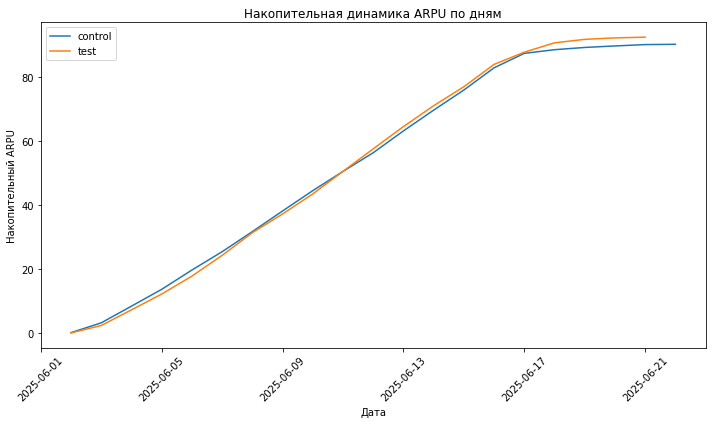

In [27]:
df_new_correct_control['event_dt'] = pd.to_datetime(df_new_correct_control['event_ts']).dt.date
df_new_correct_test['event_dt'] = pd.to_datetime(df_new_correct_test['event_ts']).dt.date

df_new_correct_control['amount'] = df_new_correct_control['amount'].fillna(0)
df_new_correct_test['amount'] = df_new_correct_test['amount'].fillna(0)

n_users_control = df_new_correct_control['user_id'].nunique()
n_users_test = df_new_correct_test['user_id'].nunique()


daily_control = (
    df_new_correct_control.groupby('event_dt', as_index=False)['amount']
    .sum()
    .sort_values('event_dt')
)

daily_test = (
    df_new_correct_test.groupby('event_dt', as_index=False)['amount']
    .sum()
    .sort_values('event_dt')
)


daily_control['cum_revenue'] = daily_control['amount'].cumsum()
daily_control['cum_arpu'] = daily_control['cum_revenue'] / n_users_control

daily_test['cum_revenue'] = daily_test['amount'].cumsum()
daily_test['cum_arpu'] = daily_test['cum_revenue'] / n_users_test

plt.figure(figsize=(10, 6))
plt.plot(daily_control['event_dt'], daily_control['cum_arpu'], label='control')
plt.plot(daily_test['event_dt'], daily_test['cum_arpu'], label='test')
plt.title('Cumulative ARPU by day')
plt.xlabel('Date')
plt.ylabel('Cumulative ARPU')
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

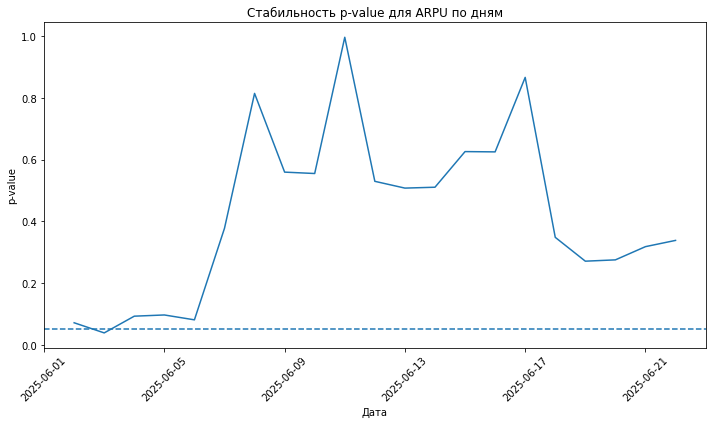

In [28]:
user_day_control = (
    df_new_correct_control.groupby(['event_dt', 'user_id'], as_index=False)['amount']
    .sum()
)

user_day_test = (
    df_new_correct_test.groupby(['event_dt', 'user_id'], as_index=False)['amount']
    .sum()
)

all_days = sorted(set(user_day_control['event_dt']).union(set(user_day_test['event_dt'])))

all_users_control = df_new_correct_control['user_id'].unique()
all_users_test = df_new_correct_test['user_id'].unique()

pvalues = []

for day in all_days:
    control_to_day = user_day_control[user_day_control['event_dt'] <= day]
    test_to_day = user_day_test[user_day_test['event_dt'] <= day]

    control_user_revenue = control_to_day.groupby('user_id')['amount'].sum()
    test_user_revenue = test_to_day.groupby('user_id')['amount'].sum()

    control_user_revenue = control_user_revenue.reindex(all_users_control, fill_value=0)
    test_user_revenue = test_user_revenue.reindex(all_users_test, fill_value=0)

    stat, pval = ttest_ind(control_user_revenue, test_user_revenue, equal_var=False)
    pvalues.append(pval)

pvalue_df = pd.DataFrame({
    'event_dt': all_days,
    'p_value': pvalues
})

plt.figure(figsize=(10, 6))
plt.plot(pvalue_df['event_dt'], pvalue_df['p_value'])
plt.axhline(y=0.05, linestyle='--')
plt.title('p-value stability for ARPU by day')
plt.xlabel('Date')
plt.ylabel('p-value')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

The cumulative ARPU curves of the control and test groups run almost identically throughout the experiment. The p-value chart is almost always above 0.05, so we cannot conclude that the key metric differs significantly between control and test.

Therefore, no statistically significant differences were found in the key metric.

**ARPU:**
No statistically significant difference between the test and control groups (p-value = 0.3383). The new feature had no significant effect on average revenue per user.

**CR registration → first deposit:**
No statistically significant difference (p-value = 0.1205). The new feature did not significantly affect the transition to the first deposit.

**CR first deposit → second deposit:**
The difference between the groups is statistically significant (p-value = 0.0000). The new feature significantly affected the probability of a second deposit.

**ARPPU:**
The difference between the test and control groups is also statistically significant (p-value = 0.0400). The new feature significantly affected average revenue per paying user.

---

### 4. Change in deposit amount per paying user

The new feature may have changed user behavior.
- Users who used to deposit small amounts may have become more cautious, reduced their investments or stopped paying altogether. This would show up as a lower 25th percentile of deposit amounts in the test group.
- Users inclined to invest larger amounts may have become more engaged and deposit more. This would show up as a higher 75th percentile.

Using bootstrap, compare the differences in the 25th, 50th and 75th percentiles of total deposits per paying user between the control and test groups: build confidence intervals for each difference, interpret them against the hypotheses above and visualize the result.

In [29]:
payer_control = (
    df_new_correct_control.groupby('user_id')['amount']
    .sum()
)

payer_test = (
    df_new_correct_test.groupby('user_id')['amount']
    .sum()
)

control = payer_control.values
test = payer_test.values

In [30]:
np.random.seed(42)

n_iterations = 1000
percentiles = [25, 50, 75]

boot_diffs = {p: [] for p in percentiles}

for i in range(n_iterations):
    boot_control = np.random.choice(control, size=len(control), replace=True)
    boot_test = np.random.choice(test, size=len(test), replace=True)

    for p in percentiles:
        perc_control = np.percentile(boot_control, p)
        perc_test = np.percentile(boot_test, p)
        boot_diffs[p].append(perc_test - perc_control)

for p in percentiles:
    boot_diffs[p] = np.array(boot_diffs[p])

    ci = np.percentile(boot_diffs[p], [2.5, 97.5])
    mean_diff = boot_diffs[p].mean()

    print(f'{p}th percentile:')
    print(f'Difference (test - control): {mean_diff:.2f}')
    print(f'95% CI: [{ci[0]:.2f}, {ci[1]:.2f}]')
    print()

25-й перцентиль:
Разница (test - control): 0.00
95% ДИ: [0.00, 0.00]

50-й перцентиль:
Разница (test - control): -49.31
95% ДИ: [-54.00, -44.50]

75-й перцентиль:
Разница (test - control): -6.71
95% ДИ: [-15.00, 0.00]



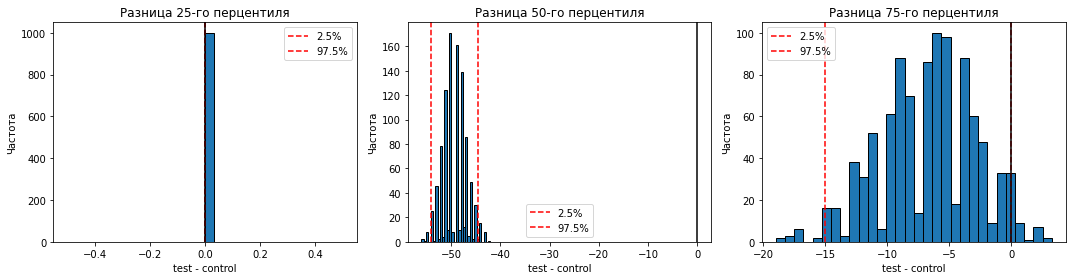

In [31]:
plt.figure(figsize=(15, 4))

for i, p in enumerate(percentiles, 1):
    ci = np.percentile(boot_diffs[p], [2.5, 97.5])

    plt.subplot(1, 3, i)
    plt.hist(boot_diffs[p], bins=30, edgecolor='black')
    plt.axvline(ci[0], color='red', linestyle='--', label='2.5%')
    plt.axvline(ci[1], color='red', linestyle='--', label='97.5%')
    plt.axvline(0, color='black', linestyle='-')
    plt.title(f'Difference in {p}th percentile')
    plt.xlabel('test - control')
    plt.ylabel('Frequency')
    plt.legend()

plt.tight_layout()
plt.show()

The bootstrap results show that the hypothesis was not confirmed. For the 25th percentile, the difference between the test and control groups is 0 and the confidence interval is also [0; 0], so users with small deposits show no change.

For the 50th percentile, the difference is negative and the confidence interval lies entirely below zero, so the median deposit amount in the test group is statistically significantly lower than in the control group. The typical paying user in the test group deposits less.

For the 75th percentile, the difference is also negative, but the confidence interval reaches zero, so no statistically significant growth in large deposits was found.

Overall, the new feature did not increase the activity of users with large investments and did not reduce deposits among users with small ones, but it is associated with a smaller typical deposit amount per paying user.

The drop in the median can be explained by a shift in the deposit structure toward smaller amounts. The new feature probably encouraged users to make small deposits more often but did not lead to larger top-ups.

---

### 5. Conclusions

**Overall conclusion.** The new feature did not lead to a statistically significant change in the key metric (ARPU) and did not significantly affect conversion from registration to first deposit. However, it had a significant effect on later stages of the user journey: in the test group, conversion from first to second deposit and ARPPU changed significantly.

The funnel analysis shows that the feature worsened onboarding completion for some users, but those who reached the lower funnel stages were more active in the test group.

The bootstrap analysis also showed a lower median deposit amount, which may indicate a shift toward smaller top-ups. Overall, the feature did not improve total revenue per user, but it noticeably changed the behavior of paying users at the later stages of the funnel.